<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Risk/VaR_CVaR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
VaR (Value at Risk): The potential loss in value of an asset/portfolio given:
                    1) A specific time period
                    2) A confidence level

CVaR (Conditional VaR): Also called as ES(Expected shortfall)
                      The average of losses beyond the VaR for a given confidence level.
'''

'''
This notebook contains:

1) VaR using 3 methods
1.a) Historical
1.b) Parametric
1.c) Simulation(Monte carlo)

2) CVaR using 3 methods
2.a) Historical
2.b) Parametric
2.c) Simulation
'''

/tmp/ipykernel_3484/2259645817.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3484/2259645817.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3484/2259645817.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_3484/2259645817.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date, multi_leve

Date
2008-05-05    0.007044
2008-05-06    0.016379
2008-05-07    0.004760
2008-05-08    0.002001
2008-05-09   -0.001310
                ...   
2023-04-18    0.004562
2023-04-19    0.005546
2023-04-20   -0.008346
2023-04-21   -0.004260
2023-04-24   -0.002698
Length: 3769, dtype: float64
27506.277253676817


(array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.]),
 array([27505.77725368, 27505.87725368, 27505.97725368, 27506.07725368,
        27506.17725368, 27506.27725368, 27506.37725368, 27506.47725368,
        27506.57725368, 27506.67725368, 27506.77725368]),
 <BarContainer object of 10 artists>)

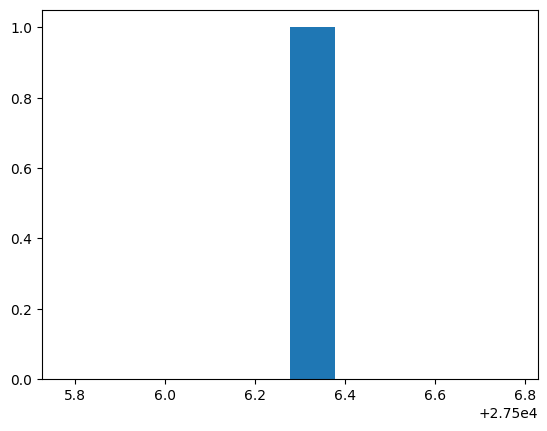

In [62]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import datetime as dt

# Download and close prices/returns data for a time period
years = 15
#start_date = dt.datetime.today() - dt.timedelta(days=365*years)
#end_date = dt.datetime.today()
start_date = '2008-04-28'
end_date = '2023-04-25'

tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']
adj_close = pd.DataFrame()

for ticker in tickers:
  # Use multi_level_index=False to prevent MultiIndex columns and retrieve the adjusted 'Close'
  data = yf.download(ticker, start=start_date, end=end_date, multi_level_index=False)
  adj_close[ticker] = data['Close']

# Log Returns
log_ret = np.log(adj_close / adj_close.shift(1))
log_ret.dropna(inplace=True)

# Portfolio
# Weighing equally weighted
weights = np.array([1/len(tickers)]*len(tickers))

# Portfolio historical returns
p_ret = (log_ret * weights).sum(axis=1)

'''VaR Historical calculations'''
# Time period(days) and confidence level
n = 5
confidence_level = 0.95
Portfolio_value = 1000000

p_ndays_ret = p_ret.rolling(window=n).sum()
p_ndays_ret.dropna(inplace=True)
print(p_ndays_ret)

VaR = -np.percentile(p_ndays_ret, (1-confidence_level)*100)*Portfolio_value
print(VaR)

# visualisations

In [44]:
'''VaR Paraametric calculations'''



3812.039813952717


(array([2.000e+00, 4.000e+00, 1.000e+00, 1.200e+01, 6.800e+01, 4.240e+02,
        1.405e+03, 5.370e+02, 4.300e+01, 7.000e+00]),
 array([-21181.77392374, -17861.61622897, -14541.45853419, -11221.30083941,
         -7901.14314464,  -4580.98544986,  -1260.82775508,   2059.32993969,
          5379.48763447,   8699.64532925,  12019.80302403]),
 <BarContainer object of 10 artists>)

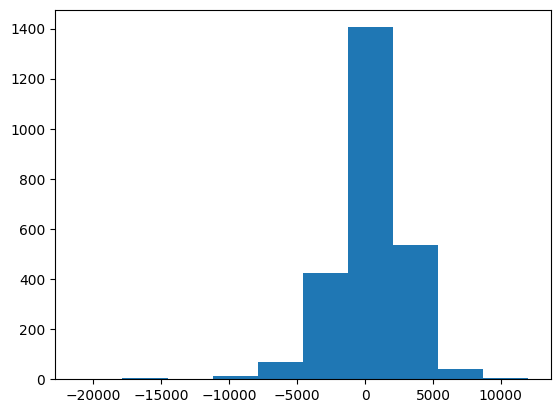

In [11]:
help(yf.download)

Help on function download in module yfinance.multi:

download(
    tickers,
    start=None,
    end=None,
    actions=False,
    threads=True,
    ignore_tz=None,
    group_by='column',
    auto_adjust=None,
    back_adjust=False,
    repair=False,
    keepna=False,
    progress=True,
    period=None,
    interval='1d',
    prepost=False,
    proxy=<object object at 0x7c041afbf060>,
    rounding=False,
    timeout=10,
    session=None,
    multi_level_index=True
) -> Optional[pandas.core.frame.DataFrame]
    Download yahoo tickers
    :Parameters:
        tickers : str, list
            List of tickers to download
        period : str
            Valid periods: 1d,5d,1mo,3mo,6mo,1y,2y,5y,10y,ytd,max
            Default: 1mo
            Either Use period parameter or use start and end
        interval : str
            Valid intervals: 1m,2m,5m,15m,30m,60m,90m,1h,1d,5d,1wk,1mo,3mo
            Intraday data cannot extend last 60 days
        start: str
            Download start date str

In [ ]:
# Time period(days) and confidence level
n = 7
confidence_level = 0.95
Portfolio_value = 100



In [ ]:
'''
USE ANNUALIZED RETURNS AND STANDARD DEVIATION FOR THE FOLLOWING CALCULATIONS:
VaR calculations :VaR = mu - zeta * std.dev
VaR is a value therefore convert this into value based on portfolio
VaR = (mu - Portfolio_value * zeta * std.dev * sqrt(n/252))
a)  Historical
'''
mu_daily = close['returns'].mean()
mu_ann = mu_daily * 252
print(mu_ann)
expected_value = (1+mu_ann) * (n/252) * Portfolio_value
print(expected_value)

sorted_returns = close['returns'].sort_values()
var_cutoff = np.percentile(sorted_returns, 100*(1-confidence_level))
print(var_cutoff)
VaR = expected_value - Portfolio_value * var_cutoff * np.sqrt(n/252)
print(VaR)

In [30]:
sorted_returns

,returns
Date,
2020-03-16,-0.109423
2020-03-12,-0.095677
2020-03-09,-0.078095
2020-06-11,-0.057649
2020-03-18,-0.050633
...,...
2022-11-10,0.054954
2020-03-26,0.058390
2020-04-06,0.067166


In [25]:
close.dropna()

Ticker,SPY,returns
Date,,
2020-01-03,293.154999,-0.007572
2020-01-06,294.273407,0.003815
2020-01-07,293.445923,-0.002812
2020-01-08,295.009918,0.005330
2020-01-09,297.010284,0.006781
...,...,...
2025-01-24,596.256165,-0.002919
2025-01-27,587.821960,-0.014145
2025-01-28,592.872681,0.008592
